# Visualizing a Demo

Awpy allows you to easily visualize Counter-Strike 2 data. We provide basic gif and heatmap creation functions. First, start by parsing a demo.

In [1]:
import sys
import os

# Get the absolute path to the 'awpy' folder
awpy_path = os.path.abspath(os.path.join(os.getcwd(), '..', '..', 'awpy'))

# Add it to sys.path
if awpy_path not in sys.path:
    sys.path.insert(0, awpy_path)

# Confirm it's in the path
#print(sys.path)

In [2]:
import os
demos_folder = "../../../../../data/cs2_demos/"
demo_folder = "../../../../../data/cs2_demos/iem-katowice-2025-natus-vincere-vs-spirit-bo3-YtA5gkUdrceGTAe_xkPfG-"
demo_path = os.listdir(demo_folder)[4]
demo_path

'natus-vincere-vs-spirit-m3-nuke.dem'

In [3]:
from awpy import Demo

# Demo: https://www.hltv.org/matches/2372746/spirit-vs-natus-vincere-blast-premier-spring-final-2024 (de_dust2, Map 2)
dem = Demo(demo_folder + '/' + demo_path, verbose=False)
dem.parse(player_props=["health", "armor_value", "pitch", "yaw"])

## Plotting a tick

You can plot a single frame with `from awpy.plot import plot`. A list of useful visual settings is found in `from awpy.plot import PLOT_SETTINGS`.

plotting magixx (ct) at 1048.6517333984375, -439.3125, -597.96875
plotting w0nderful (t) at 858.6979370117188, -1894.907958984375, -407.96875
plotting chopper (ct) at 907.9993286132812, -320.53271484375, -639.96875
plotting Aleksib (t) at 620.1593017578125, -1216.49951171875, -563.46875
plotting donk (ct) at 1174.8311767578125, -994.3734130859375, -767.96875
plotting iM (t) at 481.89276123046875, 92.25279998779297, -639.96875
plotting zont1x (ct) at 273.28350830078125, -1323.3150634765625, -769.7734375
plotting jL (t) at 943.9660034179688, -702.822265625, -767.96875
plotting SH1R0 (ct) at 1695.257080078125, -2045.1483154296875, -415.96875
plotting b1t (t) at 1230.67041015625, -1407.1375732421875, -415.96875
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_anc

(<Figure size 1024x1024 with 1 Axes>, <Axes: >)

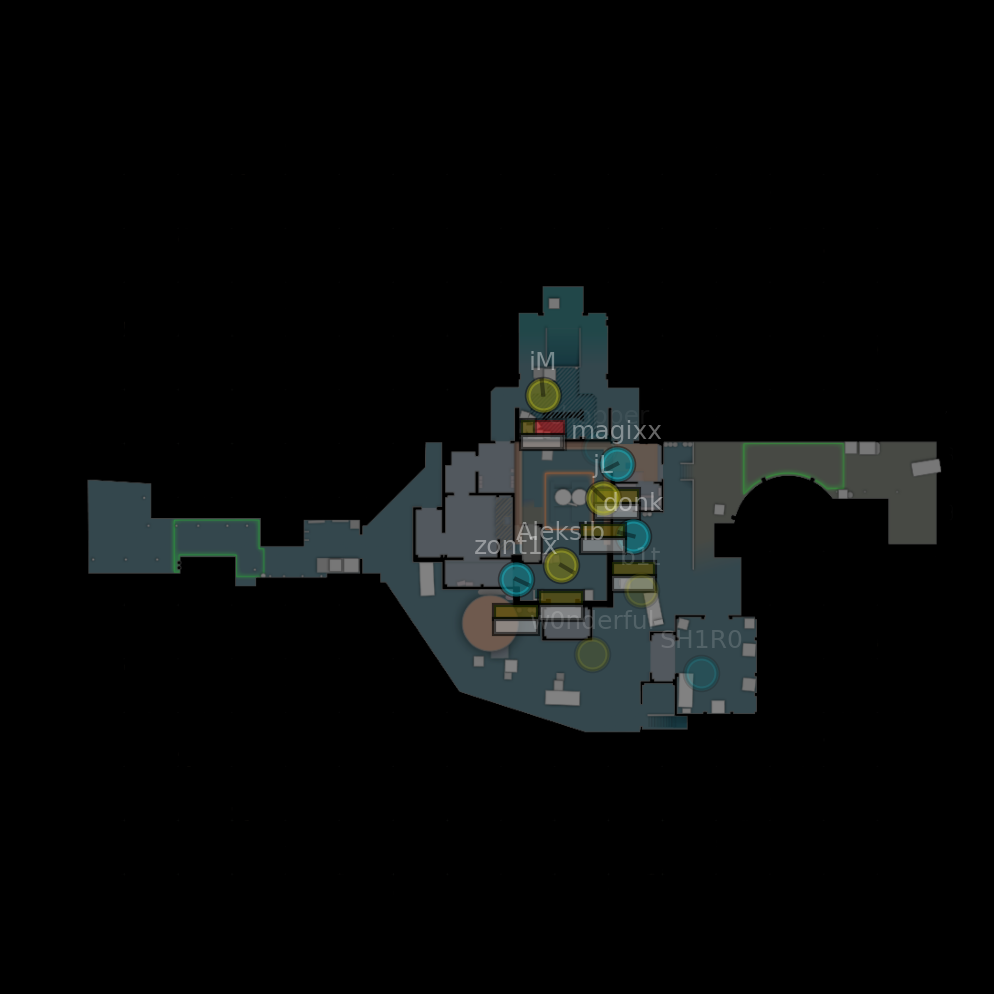

In [4]:
import polars as pl
from awpy.plot import plot, PLOT_SETTINGS

# Get a random tick
frame_df = dem.ticks.filter(pl.col("tick") == dem.ticks["tick"].unique()[14345])
frame_df = frame_df[
    ["X", "Y", "Z", "health", "armor", "pitch", "yaw", "side", "name"]
]

points = []
point_settings = []

for row in frame_df.iter_rows(named=True):
    points.append((row["X"], row["Y"], row["Z"]))
    print(f"plotting {row['name']} ({row['side']}) at {row['X']}, {row['Y']}, {row['Z']}")

    # Determine team and corresponding settings
    settings = PLOT_SETTINGS[row["side"]].copy()

    # Add additional settings
    settings.update(
        {
            "hp": row["health"],
            "armor": row["armor"],
            "direction": (row["pitch"], row["yaw"]),
            "label": row["name"],
        }
    )

    point_settings.append(settings)

plot(map_name="de_nuke", points=points, point_settings=point_settings)

## Gif

Oftentimes, we want to plot a series of frames, which we can do with `from awpy.plot import gif`. Below, we plot the every 128th tick for round 1 as a gif. It can take a while to create, so please be patient!

In [6]:
from awpy.plot import gif, PLOT_SETTINGS
from tqdm import tqdm

frames = []

for tick in tqdm(dem.ticks.filter(pl.col("round_num") == 1)["tick"].unique().to_list()[::128]):
    frame_df = dem.ticks.filter(pl.col("tick") == tick)
    frame_df = frame_df[
        ["X", "Y", "Z", "health", "armor", "pitch", "yaw", "side", "name"]
    ]

    points = []
    point_settings = []

    for row in frame_df.iter_rows(named=True):
        points.append((row["X"], row["Y"], row["Z"]))

        # Determine team and corresponding settings
        settings = PLOT_SETTINGS[row["side"]].copy()

        # Add additional settings
        settings.update(
            {
                "hp": row["health"],
                "armor": row["armor"],
                "direction": (row["pitch"], row["yaw"]),
                "label": row["name"],
            }
        )

        point_settings.append(settings)

    frames.append({"points": points, "point_settings": point_settings})

print("Finished processing frames. Creating gif...")
gif("de_nuke", frames, "de_nuke.gif", duration=100)

100%|██████████████████████████████████████████████████████████████████████████████████| 47/47 [00:00<00:00, 695.96it/s]


Finished processing frames. Creating gif...


  0%|                                                                                            | 0/47 [00:00<?, ?it/s]

dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke

  2%|█▊                                                                                  | 1/47 [00:00<00:09,  4.67it/s]

...

 94%|█████████████████████████████████████████████████████████████████████████████▋     | 44/47 [00:08<00:00,  5.37it/s]

dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke

 98%|█████████████████████████████████████████████████████████████████████████████████▏ | 46/47 [00:09<00:00,  5.21it/s]

dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke', 'de_overpass', 'de_train', 'de_vertigo', 'workshop_preview'])
dict_keys(['ar_baggage', 'ar_shoots', 'cs_italy', 'cs_office', 'de_ancient', 'de_anubis', 'de_dust', 'de_dust2', 'de_inferno', 'de_mirage', 'de_nuke

100%|███████████████████████████████████████████████████████████████████████████████████| 47/47 [00:09<00:00,  5.10it/s]


## Heatmap

Finally, you can also create heatmaps. Below, we create heatmaps for a random sample of 100,000 player locations in the demo. The available `method` options are `hex`, `hist` and `kde`. You will also want to play with the `size` parameter. The values shown below are good starting points for the corresponding `method`, but it will depend on what you are visualizing.

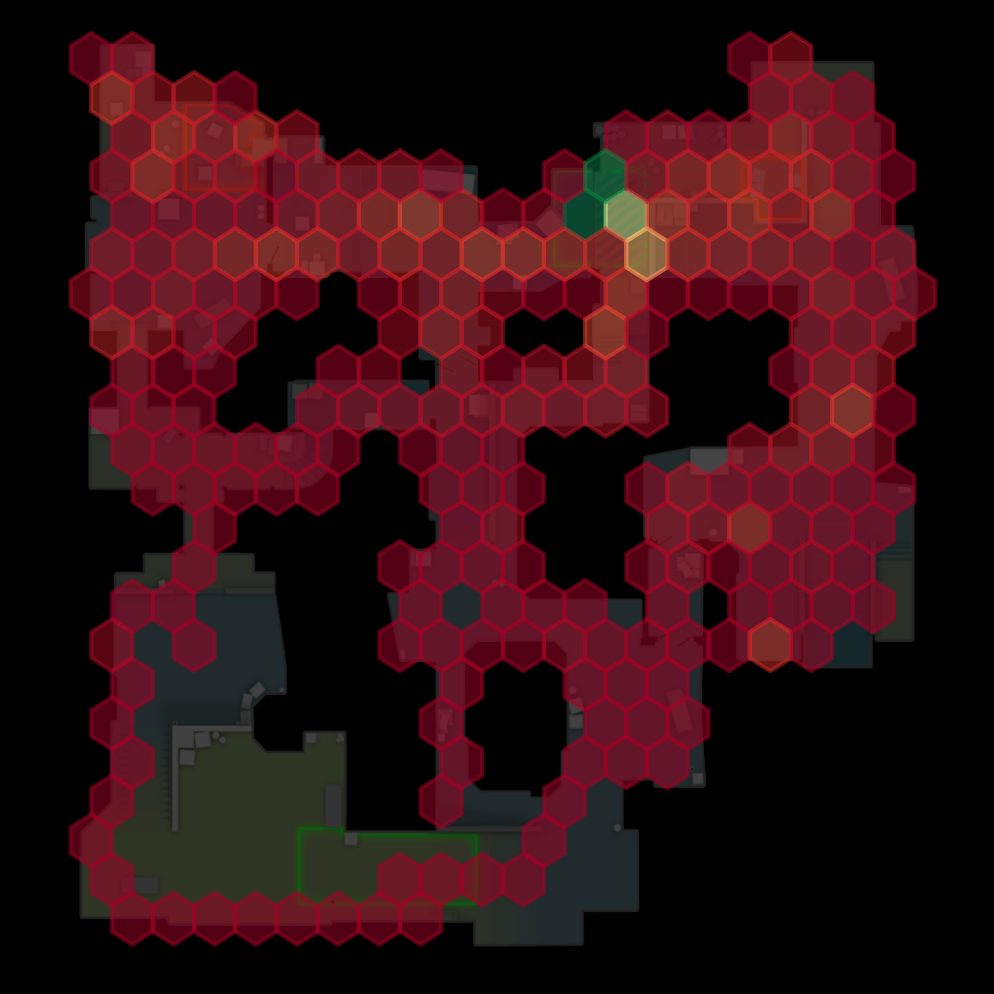

In [25]:
from awpy.plot import heatmap

player_locations = list(
    dem.ticks.filter(pl.col("health") > 0, pl.col("side") == "ct")[["X", "Y", "Z"]].sample(100000).iter_rows()
)
fig, ax = heatmap(map_name="de_dust2", points=player_locations, method="hex", size=20)

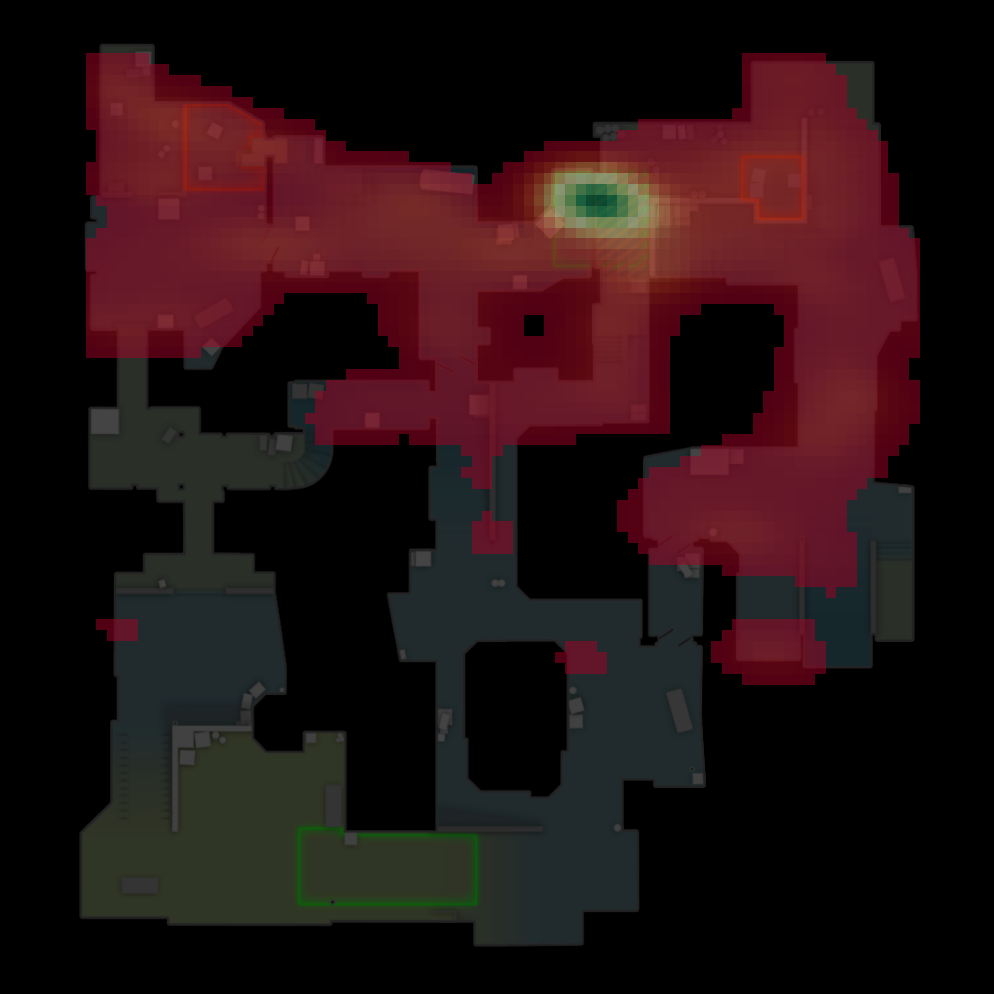

In [27]:
from awpy.plot import heatmap

player_locations = list(
    dem.ticks.filter(pl.col("health") > 0, pl.col("side") == "ct")[["X", "Y", "Z"]].sample(100000).iter_rows()
)
fig, ax = heatmap(
    map_name="de_dust2",
    points=player_locations,
    method="kde",
    size=80,
    kde_lower_bound=0.01
)